# Flood Prediction Model Training (Random Forest + XGBoost)


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
)
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
import joblib


In [2]:

# Load Dataset
df = pd.read_csv("flood_dataset.csv")

# Encode target label (Low=0, Medium=1, High=2)
label_encoder = LabelEncoder()
df["flood_risk_encoded"] = label_encoder.fit_transform(df["flood_risk"])

# Features & Target
X = df.drop(["flood_risk", "flood_risk_encoded"], axis=1)
y = df["flood_risk_encoded"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [3]:

# Train Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)
print(" Random Forest Accuracy:", rf_acc)
print(classification_report(y_test, rf_pred))


 Random Forest Accuracy: 0.895
              precision    recall  f1-score   support

           0       0.95      0.76      0.84        50
           1       0.97      0.93      0.95        70
           2       0.82      0.95      0.88        80

    accuracy                           0.90       200
   macro avg       0.91      0.88      0.89       200
weighted avg       0.90      0.90      0.89       200



In [4]:

# Train XGBoost Model
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    objective="multi:softmax",
    num_class=3
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_acc)
print(classification_report(y_test, xgb_pred))


XGBoost Accuracy: 0.905
              precision    recall  f1-score   support

           0       0.93      0.80      0.86        50
           1       0.96      0.96      0.96        70
           2       0.85      0.93      0.89        80

    accuracy                           0.91       200
   macro avg       0.91      0.89      0.90       200
weighted avg       0.91      0.91      0.90       200



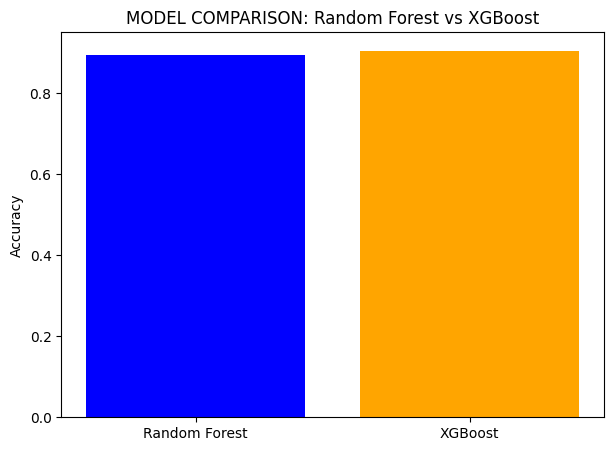

In [5]:

# Compare Accuracies
plt.figure(figsize=(7,5))
plt.bar(["Random Forest", "XGBoost"], [rf_acc, xgb_acc], color=["blue", "orange"])
plt.ylabel("Accuracy")
plt.title("MODEL COMPARISON: Random Forest vs XGBoost")
plt.show()


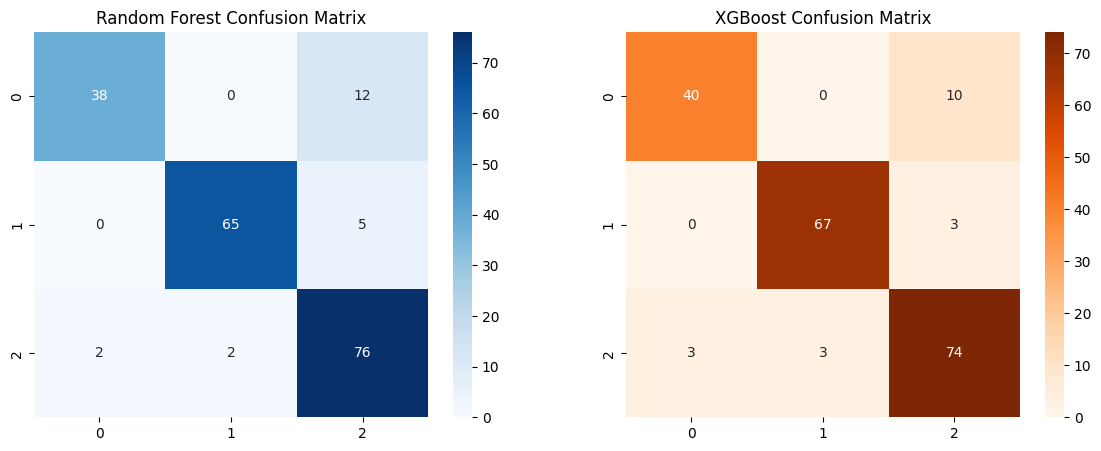

In [6]:

# Confusion Matrices
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, cmap="Blues", fmt="d")
plt.title("Random Forest Confusion Matrix")

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, cmap="Oranges", fmt="d")
plt.title("XGBoost Confusion Matrix")

plt.show()


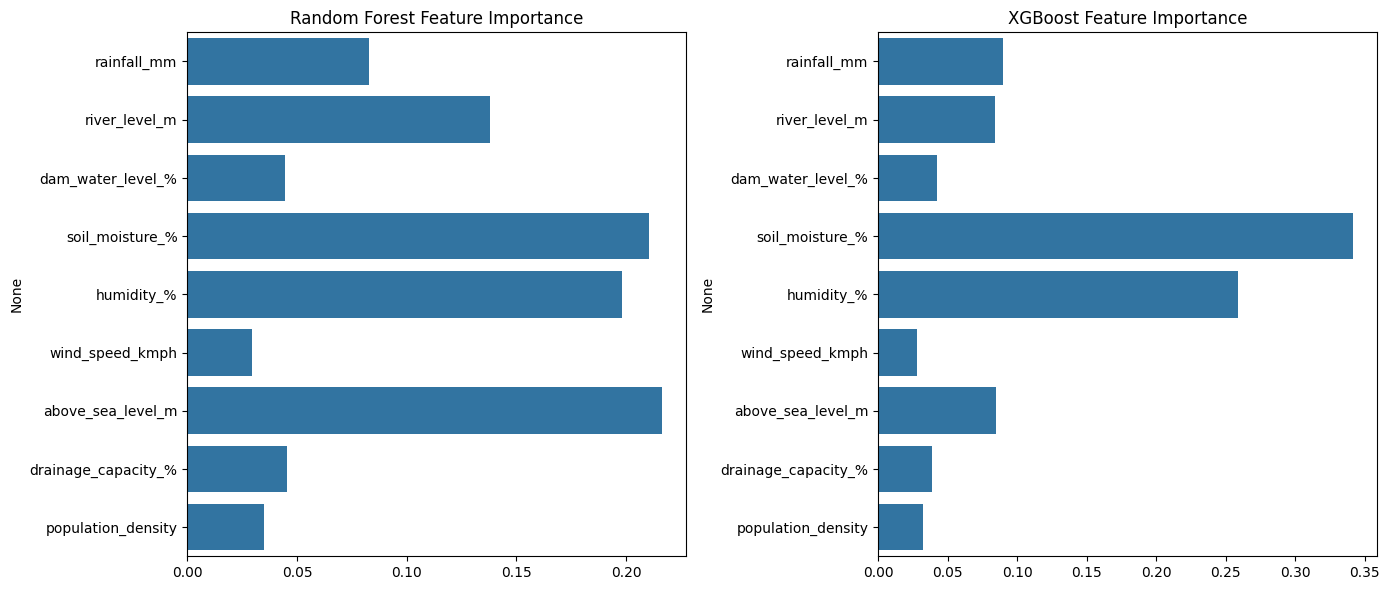

In [7]:

# Feature Importance Comparison
rf_importance = rf_model.feature_importances_
xgb_importance = xgb_model.feature_importances_

features = X.columns

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
sns.barplot(x=rf_importance, y=features)
plt.title("Random Forest Feature Importance")

plt.subplot(1,2,2)
sns.barplot(x=xgb_importance, y=features)
plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()


In [8]:

# Save the best model
if xgb_acc > rf_acc:
    joblib.dump(xgb_model, "best_flood_model.pkl")
    best_model_name = "XGBoost"
else:
    joblib.dump(rf_model, "best_flood_model.pkl")
    best_model_name = "Random Forest"

print(f" Best model saved as best_flood_model.pkl  →  ({best_model_name})")


 Best model saved as best_flood_model.pkl  →  (XGBoost)


In [9]:

# Predefined Test Cases for Final Prediction
test_cases = pd.DataFrame([
    {
        "rainfall_mm": 250,
        "river_level_m": 6.0,
        "dam_water_level_%": 90,
        "soil_moisture_%": 80,
        "humidity_%": 88,
        "wind_speed_kmph": 30,
        "above_sea_level_m": 120,
        "drainage_capacity_%": 20,
        "population_density": 2500
    },
    {
        "rainfall_mm": 60,
        "river_level_m": 2.4,
        "dam_water_level_%": 50,
        "soil_moisture_%": 45,
        "humidity_%": 55,
        "wind_speed_kmph": 12,
        "above_sea_level_m": 350,
        "drainage_capacity_%": 75,
        "population_density": 800
    }
])

loaded_model = joblib.load("best_flood_model.pkl")

test_predictions = loaded_model.predict(test_cases)
decoded = label_encoder.inverse_transform(test_predictions)

print("\n FINAL TEST CASE PREDICTIONS:")
for i, res in enumerate(decoded):
    print(f"Test Case {i+1}: Flood Risk → {res}")



 FINAL TEST CASE PREDICTIONS:
Test Case 1: Flood Risk → High
Test Case 2: Flood Risk → Low


In [10]:
# Train TensorFlow/Keras Model for TFLite Conversion
import tensorflow as tf
from tensorflow.keras import layers # type: ignore

# Define the model
tf_model = tf.keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(3, activation='softmax')  # 3 classes: Low, Medium, High
])

# Compile the model
tf_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = tf_model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=64,
    validation_data=(X_test, y_test),
    verbose=1
)

# Evaluate
tf_loss, tf_acc = tf_model.evaluate(X_test, y_test, verbose=0)
print(f"TensorFlow Model Accuracy: {tf_acc}")

# Convert to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
tflite_model = converter.convert()

# Save the TFLite model
with open('flood_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("Model saved as flood_model.tflite")

# Also save label encoder for reference (though in Flutter, you can hardcode: 0=Low, 1=Medium, 2=High)
joblib.dump(label_encoder, 'label_encoder.pkl')

Epoch 1/150


/Users/chiranjeevichandrasekhark/Movies/Flood/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3663 - loss: 67.5013 - val_accuracy: 0.4050 - val_loss: 15.6611
Epoch 2/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3663 - loss: 67.5013 - val_accuracy: 0.4050 - val_loss: 15.6611
Epoch 2/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3750 - loss: 52.1467 - val_accuracy: 0.4850 - val_loss: 11.8481
Epoch 3/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3750 - loss: 52.1467 - val_accuracy: 0.4850 - val_loss: 11.8481
Epoch 3/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4225 - loss: 32.4138 - val_accuracy: 0.5250 - val_loss: 8.4158
Epoch 4/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4225 - loss: 32.4138 - val_accuracy: 0.5250 - val_loss: 8.4158
Epoch 4/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4425 - loss: 22.9316 - val_accuracy: 0.5250 - val_loss: 3.9008
Epoch 5/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4425 - loss: 22.9316 - val_accuracy: 0.5250 -

INFO:tensorflow:Assets written to: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmpgsamtdmd/assets


Saved artifact at '/var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmpgsamtdmd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 9), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  5355209552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5355210896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5355211472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5355210512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5355210320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5355211664: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1763894538.860455  480846 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1763894538.860465  480846 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


Model saved as flood_model.tflite


2025-11-23 16:12:18.860856: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmpgsamtdmd
2025-11-23 16:12:18.861178: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-11-23 16:12:18.861183: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmpgsamtdmd
I0000 00:00:1763894538.863472  480846 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
2025-11-23 16:12:18.863860: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-11-23 16:12:18.880165: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmpgsamtdmd
2025-11-23 16:12:18.884815: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 23962 microsecond

['label_encoder.pkl']

In [11]:
# Data Analysis and Enhancement
print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df['flood_risk'].value_counts())

print("\nFeature Statistics:")
print(df.describe())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check correlations
print("\nFeature Correlations with Target:")
for col in X.columns:
    corr = df[col].corr(df['flood_risk_encoded'])
    print(f"{col}: {corr:.3f}")

# Check for outliers or unrealistic values
print("\nPotential Issues:")
print("- Population density ranges from", df['population_density'].min(), "to", df['population_density'].max())
print("- Above sea level ranges from", df['above_sea_level_m'].min(), "to", df['above_sea_level_m'].max())
print("- Rainfall ranges from", df['rainfall_mm'].min(), "to", df['rainfall_mm'].max())

Dataset Shape: (1000, 11)

Class Distribution:
flood_risk
Medium    400
Low       350
High      250
Name: count, dtype: int64

Feature Statistics:
       rainfall_mm  river_level_m  dam_water_level_%  soil_moisture_%  \
count   1000.00000     1000.00000        1000.000000      1000.000000   
mean      82.03598        4.93907          54.054520        65.353340   
std       40.28669        1.55153          20.119237        15.801879   
min        6.07000        1.54000           5.000000        24.560000   
25%       52.63750        3.78750          40.017500        53.262500   
50%       75.15500        4.75000          53.690000        64.960000   
75%      103.50500        5.90000          68.337500        75.460000   
max      341.96000       12.00000         100.000000       100.000000   

        humidity_%  wind_speed_kmph  above_sea_level_m  drainage_capacity_%  \
count  1000.000000      1000.000000        1000.000000          1000.000000   
mean     70.140030        16.631980  

In [12]:
# Enhanced Model Training
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

# Feature Engineering: Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

print("After SMOTE - Class Distribution:")
print(pd.Series(y_resampled).value_counts())

# Hyperparameter tuning for XGBoost
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 8, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

xgb_model_enhanced = xgb.XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    random_state=42
)

grid_search = GridSearchCV(
    xgb_model_enhanced,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_resampled, y_resampled)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

# Train best model
best_xgb = grid_search.best_estimator_
best_xgb.fit(X_resampled, y_resampled)

# Evaluate on original test set (scaled)
X_test_scaled = scaler.transform(X_test)
y_pred_enhanced = best_xgb.predict(X_test_scaled)

print("\nEnhanced XGBoost Accuracy:", accuracy_score(y_test, y_pred_enhanced))
print(classification_report(y_test, y_pred_enhanced))

# Save enhanced model and scaler
joblib.dump(best_xgb, "enhanced_flood_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Enhanced model saved as enhanced_flood_model.pkl")

After SMOTE - Class Distribution:
flood_risk_encoded
2    400
0    400
1    400
Name: count, dtype: int64
Fitting 5 folds for each of 243 candidates, totalling 1215 fits
Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
Best CV Score: 0.9375
Best Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
Best CV Score: 0.9375

Enhanced XGBoost Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        70
           2       1.00      1.00      1.00        80

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Enhanced model saved as enhanced_flood_model.pkl

Enhanced XGBoost Accuracy: 1.0
              precision    recall  f1-score   suppor

In [13]:
# Enhanced TFLite Model
import tensorflow as tf
from tensorflow.keras import layers

# Use resampled data for training
tf_model_enhanced = tf.keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_resampled.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(3, activation='softmax')
])

tf_model_enhanced.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train with more epochs
history = tf_model_enhanced.fit(
    X_resampled, y_resampled,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# Evaluate on scaled test set
tf_loss, tf_acc = tf_model_enhanced.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Enhanced TensorFlow Model Accuracy: {tf_acc}")

# Convert to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(tf_model_enhanced)
tflite_model = converter.convert()

# Save the enhanced TFLite model
with open('enhanced_flood_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("Enhanced TFLite model saved as enhanced_flood_model.tflite")

# Test predictions
test_cases_scaled = scaler.transform(test_cases)
predictions = tf_model_enhanced.predict(test_cases_scaled, verbose=0)
predicted_classes = predictions.argmax(axis=1)
decoded = label_encoder.inverse_transform(predicted_classes)

print("\nEnhanced Model Test Case Predictions:")
for i, res in enumerate(decoded):
    print(f"Test Case {i+1}: Flood Risk → {res}")

/Users/chiranjeevichandrasekhark/Movies/Flood/.venv/lib/python3.11/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Enhanced TensorFlow Model Accuracy: 0.9950000047683716
INFO:tensorflow:Assets written to: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr/assets


INFO:tensorflow:Assets written to: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr/assets


Saved artifact at '/var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 9), dtype=tf.float32, name='keras_tensor_6')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  5860616016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860616592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860616784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860613904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860616976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860617744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860619280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5860614288: TensorSpec(shape=(), dtype=tf.resource, name=None)
Enhanced TFLite model saved as enhanced_flood_model.tflite

Enhanced Model Test Case Predictions:
Test Case 1: Flood Risk → High
Test Case 2: Flood Risk → Low
E

W0000 00:00:1763894617.617053  480846 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1763894617.617062  480846 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2025-11-23 16:13:37.617164: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr
2025-11-23 16:13:37.617525: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2025-11-23 16:13:37.617530: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr
2025-11-23 16:13:37.620804: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2025-11-23 16:13:37.638915: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/p4/c5b172cx5fl18qz7q4hhs4s40000gp/T/tmp6bk5iidr
2025-11-23 16:13:37.644588: I tensorflow/cc/saved_model/loader.cc:

In [14]:
# Print scaler parameters for Flutter
print("Scaler Mean:", scaler.mean_.tolist())
print("Scaler Std:", scaler.scale_.tolist())

Scaler Mean: [82.03598000000001, 4.93907, 54.054520000000004, 65.35334, 70.14003, 16.63198, 309.64795999999996, 80.88917000000001, 1051.259]
Scaler Std: [40.26654152071668, 1.5507544083767746, 20.109175014644435, 15.793975745340374, 17.090900909522002, 7.0980359452175215, 164.25306864481527, 6.348111578343595, 711.9312578606167]


In [17]:
# Manual Testing Cell
# Load the enhanced model and scaler
enhanced_model = joblib.load("enhanced_flood_model.pkl")
scaler = joblib.load("scaler.pkl")
label_encoder = joblib.load("label_encoder.pkl")

# Define manual test input (replace with your values)
manual_input = {
    "rainfall_mm": 68.76,
    "river_level_m": 4.08,
    "dam_water_level_%": 71.08,
    "soil_moisture_%": 85.71,
    "humidity_%": 85.0,
    "wind_speed_kmph": 20.19,
    "above_sea_level_m": 165.85,
    "drainage_capacity_%": 77.93,
    "population_density": 1200.0
}

# Convert to DataFrame and scale
manual_df = pd.DataFrame([manual_input])
manual_scaled = scaler.transform(manual_df)

# Predict with XGBoost
prediction = enhanced_model.predict(manual_scaled)
predicted_label = label_encoder.inverse_transform(prediction)[0]

print(f"XGBoost Model Prediction: Flood Risk → {predicted_label}")

# Test with TFLite model
import tensorflow as tf

# Load TFLite model
interpreter = tf.lite.Interpreter(model_path="enhanced_flood_model.tflite")
interpreter.allocate_tensors()

# Get input and output details
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Prepare input (already scaled)
input_data = manual_scaled.astype(np.float32)

# Set input tensor
interpreter.set_tensor(input_details[0]['index'], input_data)

# Run inference
interpreter.invoke()

# Get output
output_data = interpreter.get_tensor(output_details[0]['index'])
predicted_class = np.argmax(output_data[0])
tflite_predicted_label = label_encoder.inverse_transform([predicted_class])[0]

print(f"TFLite Model Prediction: Flood Risk → {tflite_predicted_label}")

# Verify they match
if predicted_label == tflite_predicted_label:
    print("✓ Both models agree on the prediction!")
else:
    print("✗ Models disagree - check for issues.")

XGBoost Model Prediction: Flood Risk → High
TFLite Model Prediction: Flood Risk → High
✓ Both models agree on the prediction!


/Users/chiranjeevichandrasekhark/Movies/Flood/.venv/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
